# 1. Objective

The objective of this module is to recommend movies to new users who have no previous rating history.

The system uses user preferences such as favourite genres, movies, actors and directors to recommend similar movies.

TF-IDF and Cosine Similarity are used to generate content-based movie recommendations.

The performance is evaluated using Precision, Recall, NDCG and Catalog Coverage.

# 2. Importing Libraries

The following Python libraries are used in this project:

- Pandas: To load and process dataset files.
- NumPy: To perform numerical operations.
- Scikit-learn: To implement TF-IDF and Cosine Similarity.
- Matplotlib: To create graphs and visualisations.

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

SEED = 42
np.random.seed(SEED)

print("All libraries imported successfully!")

All libraries imported successfully!


# 3. Loading Common Processed Data

The project uses the HetRec 2011 – MovieLens 2K dataset.

The following preprocessed CSV files are used:

- ratings_clean.csv
- movie_features.csv
- train_ratings.csv
- test_ratings.csv

These files contain movie ratings, movie details and training/testing data required for the recommendation system.

In [5]:
base = "../dataset/processed/"

ratings = pd.read_csv(base + "ratings_clean.csv")
movies = pd.read_csv(base + "movie_features.csv")
train = pd.read_csv(base + "train_ratings.csv")
test = pd.read_csv(base + "test_ratings.csv")

print("Ratings shape:", ratings.shape)
print("Movies shape:", movies.shape)
print("Training data shape:", train.shape)
print("Testing data shape:", test.shape)

print("\nMovie features:")
print(movies.columns.tolist())

print("\nTraining data:")
print(train.head())

Ratings shape: (855598, 9)
Movies shape: (10197, 27)
Training data shape: (683631, 9)
Testing data shape: (171808, 9)

Movie features:
['movieID', 'title', 'imdbID', 'spanishTitle', 'imdbPictureURL', 'year', 'rtID', 'rtAllCriticsRating', 'rtAllCriticsNumReviews', 'rtAllCriticsNumFresh', 'rtAllCriticsNumRotten', 'rtAllCriticsScore', 'rtTopCriticsRating', 'rtTopCriticsNumReviews', 'rtTopCriticsNumFresh', 'rtTopCriticsNumRotten', 'rtTopCriticsScore', 'rtAudienceRating', 'rtAudienceNumRatings', 'rtAudienceScore', 'rtPictureURL', 'genres', 'tags', 'actors', 'directors', 'countries', 'content']

Training data:
   userID  movieID  rating  date_day  date_month  date_year  date_hour  \
0      75      160     2.0        29          10       2006         23   
1      75     2762     3.5        29          10       2006         23   
2      75     2959     4.5        29          10       2006         23   
3      75      353     3.5        29          10       2006         23   
4      75     1215

# 4. Understanding the Problem

## 4.1 Problem Definition

The User Cold Start problem occurs when a new user joins a recommendation system without having any previous rating history.

Since the system does not know the user's interests, it becomes difficult to recommend suitable movies.

## 4.2 Sub-Objectives

1. Identify users with sufficient rating history for simulation.
2. Simulate new users by separating their ratings into onboarding and evaluation data.
3. Collect user preferences such as favourite genres, movies, actors and directors.
4. Build user profiles using TF-IDF and Cosine Similarity.
5. Generate personalised movie recommendations.
6. Evaluate recommendation performance using Precision, Recall, NDCG and Catalog Coverage.

## 4.3 Proposed Solution

The system uses a content-based recommendation approach.

It collects user preferences during onboarding and compares them with movie features to recommend relevant movies.

## 4.4 Preference Levels

- Level A: Genres only.
- Level B: Genres and favourite movies.
- Level C: Genres, favourite movies, actors and directors.

The performance of these three levels will be compared to understand how additional preferences affect recommendation quality.

# 5. Experimental Setup

## 5.1 Random Seed

A fixed random seed of 42 is used to ensure reproducible results.

## 5.2 Cold-Start User Selection

- Select users who have at least 20 ratings in the training dataset.
- Randomly select approximately 100–200 users.
- These selected users are treated as new users.
- Remove their ratings completely from the model training data.
- Keep their ratings separately for evaluation.

## 5.3 Onboarding and Evaluation Split

For each selected cold-start user:

- Sort their ratings according to time.
- Divide their ratings into two parts.
- First 50%: Onboarding data.
- Last 50%: Evaluation data.

## 5.4 Preference Simulation

Only movies rated 4.0 or higher in the onboarding data are considered liked movies.

User preferences are simulated using:

- Top 3–5 highest-rated movies.
- Top 3 favourite genres.
- Top 3 favourite actors.
- Top 3 favourite directors.

## 5.5 Experimental Levels

- Level A: Genres only.
- Level B: Genres and favourite movies.
- Level C: Genres, favourite movies, actors and directors.

## 5.6 Data Leakage Prevention

- Evaluation ratings are never used to build user profiles.
- Onboarding movies are excluded from recommendation candidates.
- Missing ratings are not filled with zero.
- Original user IDs and movie IDs are preserved.

# 6. Implementation

This section implements the User Cold Start recommendation approach.

The implementation includes the following steps:

1. Select users with sufficient rating history.
2. Simulate new users by separating their ratings into onboarding and evaluation data.
3. Extract user preferences from onboarding data.
4. Build movie feature vectors using TF-IDF.
5. Create user profiles using their preferences.
6. Calculate Cosine Similarity between user profiles and movies.
7. Generate personalised movie recommendations.

Three preference levels are implemented:

- Level A: Genres only.
- Level B: Genres and favourite movies.
- Level C: Genres, favourite movies, actors and directors.

## 6.1 Selecting Cold-Start Users

Users with at least 20 ratings are selected for the cold-start experiment.

A fixed random seed of 42 is used to randomly select up to 150 users.

These users will be treated as new users for evaluating the recommendation system.

In [6]:
SEED = 42
np.random.seed(SEED)

# Select users having at least 20 ratings
user_counts = train.groupby("userID").size()

eligible_users = user_counts[user_counts >= 20].index.to_numpy()

# Randomly select up to 150 users
rng = np.random.RandomState(SEED)

cold_users = rng.choice(
    eligible_users,
    size=min(150, len(eligible_users)),
    replace=False
)

print("Eligible users:", len(eligible_users))
print("Selected cold-start users:", len(cold_users))
print("Selected user IDs:", cold_users[:10])

Eligible users: 2029
Selected cold-start users: 150
Selected user IDs: [48076 34704 30490 70331 45881 51972 42411 13014 60325 49065]


## 6.2 Separating Cold-Start Users

The selected cold-start users are completely removed from the training dataset.

Their ratings are kept separately for the onboarding and evaluation process.

This prevents the recommendation model from using cold-start users' ratings during training.

In [7]:
# Separate selected users' ratings
cold_user_ratings = train[train["userID"].isin(cold_users)].copy()

# Remove cold-start users from training data
train_without_cold = train[~train["userID"].isin(cold_users)].copy()

print("Original training data:", train.shape)
print("Cold-start user ratings:", cold_user_ratings.shape)
print("Training data after removal:", train_without_cold.shape)

print(
    "Cold users remaining in training:",
    train_without_cold["userID"].isin(cold_users).sum()
)

Original training data: (683631, 9)
Cold-start user ratings: (46793, 9)
Training data after removal: (636838, 9)
Cold users remaining in training: 0


## 6.3 Onboarding and Evaluation Split

For each selected cold-start user, ratings are sorted according to their date and time.

The ratings are divided into two parts:

- First 50%: Onboarding data.
- Last 50%: Evaluation data.

The onboarding data is used to understand user preferences.

The evaluation data is used to measure recommendation performance.

Evaluation ratings are never used to build user profiles.

In [8]:
# Sort ratings by date and time
cold_user_ratings = cold_user_ratings.sort_values(
    ["userID", "date_year", "date_month", "date_day",
     "date_hour", "date_minute", "date_second"]
)

onboarding_parts = []
evaluation_parts = []

for user_id in cold_users:

    user_data = cold_user_ratings[
        cold_user_ratings["userID"] == user_id
    ]

    split_point = int(len(user_data) * 0.5)

    onboarding_parts.append(user_data.iloc[:split_point])
    evaluation_parts.append(user_data.iloc[split_point:])

onboarding_data = pd.concat(onboarding_parts)
evaluation_data = pd.concat(evaluation_parts)

print("Onboarding data shape:", onboarding_data.shape)
print("Evaluation data shape:", evaluation_data.shape)

print("\nSample onboarding data:")
display(onboarding_data.head())

print("\nSample evaluation data:")
display(evaluation_data.head())

Onboarding data shape: (23362, 9)
Evaluation data shape: (23431, 9)

Sample onboarding data:


,userID,movieID,rating,date_day,date_month,date_year,date_hour,date_minute,date_second
474357,48076,1967,3.5,14,3,2008,3,35,36
474371,48076,107,4.5,14,3,2008,3,36,48
474326,48076,2398,3.5,14,3,2008,3,39,37
474354,48076,1013,4.5,14,3,2008,3,40,28
474355,48076,2053,2.0,14,3,2008,3,40,31



Sample evaluation data:


,userID,movieID,rating,date_day,date_month,date_year,date_hour,date_minute,date_second
474343,48076,838,4.0,14,3,2008,4,30,13
474323,48076,40629,4.5,14,3,2008,4,33,21
474320,48076,7579,4.5,14,3,2008,4,34,22
474362,48076,7770,2.5,14,3,2008,4,34,25
474376,48076,52287,4.5,14,3,2008,4,41,21


In [9]:
# Check for overlapping user-movie pairs
onboarding_pairs = set(
    zip(onboarding_data["userID"], onboarding_data["movieID"])
)

evaluation_pairs = set(
    zip(evaluation_data["userID"], evaluation_data["movieID"])
)

overlap = onboarding_pairs.intersection(evaluation_pairs)

print("Overlapping records:", len(overlap))
print("Onboarding users:", onboarding_data["userID"].nunique())
print("Evaluation users:", evaluation_data["userID"].nunique())

Overlapping records: 0
Onboarding users: 150
Evaluation users: 150


## 6.4 Simulating User Preferences

User preferences are simulated using only the onboarding data.

The following preferences are extracted:

- Favourite movies: Top 5 highest-rated movies.
- Favourite genres: Top 3 most frequent genres.
- Favourite actors: Top 3 most frequent actors.
- Favourite directors: Top 3 most frequent directors.

Only movies with ratings of 4.0 or higher are considered liked movies.

Three preference levels are created:

- Level A: Genres only.
- Level B: Genres and favourite movies.
- Level C: Genres, favourite movies, actors and directors.

In [20]:
RELEVANT = 4.0

movie_lookup = movie_features_model.set_index("movieID")

def simulate_preferences(pool_user, level="C"):
    liked = pool_user[pool_user["rating"] >= RELEVANT].copy()

    if liked.empty:
        return None

    liked = liked.sort_values(
        "rating", ascending=False, kind="stable"
    )

    liked_ids = liked["movieID"].tolist()

    liked_features = movie_lookup.reindex(liked_ids)

    def top_tokens(column, n):
        tokens = (
            " ".join(
                liked_features[column].fillna("").astype(str)
            ).split()
        )

        if not tokens:
            return []

        return (
            pd.Series(tokens)
            .value_counts()
            .head(n)
            .index.tolist()
        )

    preferences = {
        "genres": top_tokens("genres", 3),
        "actors": [],
        "directors": [],
        "movies": []
    }

    if level in ("B", "C"):
        preferences["movies"] = liked_ids[:5]

    if level == "C":
        preferences["actors"] = top_tokens("actor_token", 3)
        preferences["directors"] = top_tokens("director_token", 3)

    return preferences

### 6.4.1 Testing User Preferences

The preference simulation function is tested on one selected cold-start user to verify that favourite genres, movies, actors and directors are extracted correctly.

In [21]:
# Select one cold-start user
sample_user = cold_users[0]

# Get only this user's onboarding ratings
sample_pool = onboarding_data[
    onboarding_data["userID"] == sample_user
]

# Generate Level C preferences
sample_preferences = simulate_preferences(
    sample_pool,
    level="C"
)

print("Sample User ID:", sample_user)
print("\nGenerated Preferences:")

for key, value in sample_preferences.items():
    print(key, ":", value)

Sample User ID: 48076

Generated Preferences:
genres : ['Comedy', 'Children', 'Adventure']
actors : ['actor_jon_voight', 'actor_cary_grant', 'actor_nicolas_cage']
directors : ['dir_jon_turteltaub', 'dir_rob_reiner', 'dir_howard_hawks']
movies : [1197, 955, 53466, 8972, 41566]


### 6.4.2 Generating Preferences for All Cold-Start Users

The preference simulation function is applied to all selected cold-start users.

Preferences are generated separately for Level A, Level B and Level C using only onboarding data.

In [22]:
# Store onboarding data separately for each user
user_onboarding = {
    user_id: onboarding_data[
        onboarding_data["userID"] == user_id
    ].copy()
    for user_id in cold_users
}

# Generate preferences for all three levels
preferences_A = {}
preferences_B = {}
preferences_C = {}

for user_id in cold_users:

    user_pool = user_onboarding[user_id]

    pref_A = simulate_preferences(user_pool, level="A")
    pref_B = simulate_preferences(user_pool, level="B")
    pref_C = simulate_preferences(user_pool, level="C")

    if pref_A is not None:
        preferences_A[user_id] = pref_A
        preferences_B[user_id] = pref_B
        preferences_C[user_id] = pref_C

print("Level A users:", len(preferences_A))
print("Level B users:", len(preferences_B))
print("Level C users:", len(preferences_C))

print("\nExample Level A:")
print(preferences_A.get(cold_users[0]))

print("\nExample Level B:")
print(preferences_B.get(cold_users[0]))

print("\nExample Level C:")
print(preferences_C.get(cold_users[0]))

Level A users: 150
Level B users: 150
Level C users: 150

Example Level A:
{'genres': ['Comedy', 'Children', 'Adventure'], 'actors': [], 'directors': [], 'movies': []}

Example Level B:
{'genres': ['Comedy', 'Children', 'Adventure'], 'actors': [], 'directors': [], 'movies': [1197, 955, 53466, 8972, 41566]}

Example Level C:
{'genres': ['Comedy', 'Children', 'Adventure'], 'actors': ['actor_jon_voight', 'actor_cary_grant', 'actor_nicolas_cage'], 'directors': ['dir_jon_turteltaub', 'dir_rob_reiner', 'dir_howard_hawks'], 'movies': [1197, 955, 53466, 8972, 41566]}


### 6.4.3 Loading Original Actor and Director Data

The original HetRec actor and director files are used to obtain accurate actor and director IDs.

These IDs are converted into unique tokens so that complete names are not incorrectly divided into individual words.

This ensures consistency between user preferences and movie features.

In [23]:
# Path to original raw dataset
raw_base = "../dataset/raw/"

# Load original actor and director data
actors_raw = pd.read_csv(
    raw_base + "movie_actors.dat",
    sep="\t",
    encoding="latin-1"
)

directors_raw = pd.read_csv(
    raw_base + "movie_directors.dat",
    sep="\t",
    encoding="latin-1"
)

print("Actor data shape:", actors_raw.shape)
print("Director data shape:", directors_raw.shape)

print("\nActor columns:", actors_raw.columns.tolist())
print("Director columns:", directors_raw.columns.tolist())

display(actors_raw.head())
display(directors_raw.head())

Actor data shape: (231742, 4)
Director data shape: (10155, 3)

Actor columns: ['movieID', 'actorID', 'actorName', 'ranking']
Director columns: ['movieID', 'directorID', 'directorName']


,movieID,actorID,actorName,ranking
0,1,annie_potts,Annie Potts,10
1,1,bill_farmer,Bill Farmer,20
2,1,don_rickles,Don Rickles,3
3,1,erik_von_detten,Erik von Detten,13
4,1,greg-berg,Greg Berg,17


,movieID,directorID,directorName
0,1,john_lasseter,John Lasseter
1,2,joe_johnston,Joe Johnston
2,3,donald_petrie,Donald Petrie
3,4,forest_whitaker,Forest Whitaker
4,5,charles_shyer,Charles Shyer


### 6.4.4 Creating Actor and Director ID Tokens

We use the original actor and director IDs to create unique tokens for each movie. This ensures that movie features and user preferences use matching tokens.

In [24]:
# Create actor ID tokens
actors_raw["actor_token"] = "actor_" + actors_raw["actorID"].astype(str)

# Select the top 5 actors for each movie
actors_raw = actors_raw.sort_values("ranking")

actor_features = (
    actors_raw.groupby("movieID")["actor_token"]
    .apply(lambda x: " ".join(x.head(5)))
    .reset_index()
)

# Create director ID tokens
directors_raw["director_token"] = (
    "dir_" + directors_raw["directorID"].astype(str)
)

director_features = (
    directors_raw.groupby("movieID")["director_token"]
    .apply(lambda x: " ".join(x))
    .reset_index()
)

# Create a separate model-ready movie feature dataset
movie_features_model = movies.copy()

# Add actor and director tokens
movie_features_model = movie_features_model.merge(
    actor_features, on="movieID", how="left"
)

movie_features_model = movie_features_model.merge(
    director_features, on="movieID", how="left"
)

# Fill missing values
for col in ["actor_token", "director_token"]:
    movie_features_model[col] = movie_features_model[col].fillna("")

# Create updated movie content
movie_features_model["content"] = (
    movie_features_model["genres"].fillna("").astype(str) + " " +
    movie_features_model["tags"].fillna("").astype(str) + " " +
    movie_features_model["actor_token"] + " " +
    movie_features_model["director_token"] + " " +
    movie_features_model["countries"].fillna("").astype(str)
)

print("Movie feature shape:", movie_features_model.shape)
print("\nSample actor tokens:")
print(movie_features_model[["movieID", "actor_token"]].head())

print("\nSample director tokens:")
print(movie_features_model[["movieID", "director_token"]].head())

Movie feature shape: (10197, 29)

Sample actor tokens:
   movieID                                        actor_token
0        1  actor_tom_hanks actor_tim_allen actor_don_rick...
1        2  actor_robin_williams actor_bonnie_hunt actor_k...
2        3  actor_jack_lemmon actor_walter_matthau actor_a...
3        4  actor_whitney_houston actor_angela_bassett act...
4        5  actor_steve_martin actor_diane_keaton actor_ma...

Sample director tokens:
   movieID       director_token
0        1    dir_john_lasseter
1        2     dir_joe_johnston
2        3    dir_donald_petrie
3        4  dir_forest_whitaker
4        5    dir_charles_shyer


## 6.5 TF-IDF and Cosine Similarity

TF-IDF converts movie content into numerical vectors. Cosine similarity measures how closely a movie matches the user's preferences.

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Convert movie content into TF-IDF vectors
tfidf = TfidfVectorizer(
    token_pattern=r"(?u)\b\w+\b"
)

tfidf_matrix = tfidf.fit_transform(
    movie_features_model["content"].fillna("")
)

print("TF-IDF matrix shape:", tfidf_matrix.shape)

# Create movie ID to row index mapping
movie_id_to_index = pd.Series(
    movie_features_model.index,
    index=movie_features_model["movieID"]
).to_dict()

print("Movie ID mapping created:", len(movie_id_to_index))

TF-IDF matrix shape: (10197, 30361)
Movie ID mapping created: 10197


## 6.6 Generating Recommendations

The recommendation function compares user preferences with movie content using TF-IDF and cosine similarity. It generates the Top-5 or Top-10 most relevant movies.

In [26]:
def recommend_movies(preferences, top_n=10, exclude_movie_ids=None):
    if not preferences:
        return pd.DataFrame()

    # Build user preference text using the same movie tokens
    preference_tokens = []

    preference_tokens.extend(preferences.get("genres", []))
    preference_tokens.extend(preferences.get("actors", []))
    preference_tokens.extend(preferences.get("directors", []))

    favourite_ids = preferences.get("movies", [])

    # Add content of favourite movies
    for movie_id in favourite_ids:
        if movie_id in movie_id_to_index:
            idx = movie_id_to_index[movie_id]
            preference_tokens.append(
                movie_features_model.iloc[idx]["content"]
            )

    preference_text = " ".join(preference_tokens)

    if not preference_text.strip():
        return pd.DataFrame()

    # Convert user preferences into TF-IDF vector
    user_vector = tfidf.transform([preference_text])

    # Calculate cosine similarity
    similarities = cosine_similarity(
        user_vector, tfidf_matrix
    ).flatten()

    # Create recommendation results
    results = movie_features_model.copy()
    results["similarity"] = similarities

    # Exclude onboarding movies and favourite movies
    excluded = set(exclude_movie_ids or [])
    excluded.update(favourite_ids)

    results = results[
        ~results["movieID"].isin(excluded)
    ]

    # Sort by similarity
    results = results.sort_values(
        "similarity", ascending=False
    )

    return results.head(top_n)[
        ["movieID", "title", "genres", "similarity"]
    ]

### 6.6.1 Testing Recommendations for One Cold-Start User

We test the recommendation system using one cold-start user from the selected users.

In [27]:
# Select one cold-start user
test_user_id = cold_users[0]

# Get this user's onboarding movie IDs
onboarding_movie_ids = user_onboarding[test_user_id]["movieID"].tolist()

# Generate recommendations for all three levels
recommendations_A = recommend_movies(
    preferences_A[test_user_id],
    top_n=10,
    exclude_movie_ids=onboarding_movie_ids
)

recommendations_B = recommend_movies(
    preferences_B[test_user_id],
    top_n=10,
    exclude_movie_ids=onboarding_movie_ids
)

recommendations_C = recommend_movies(
    preferences_C[test_user_id],
    top_n=10,
    exclude_movie_ids=onboarding_movie_ids
)

print("Test User ID:", test_user_id)

print("\nLevel A Recommendations:")
display(recommendations_A)

print("\nLevel B Recommendations:")
display(recommendations_B)

print("\nLevel C Recommendations:")
display(recommendations_C)

Test User ID: 48076

Level A Recommendations:


,movieID,title,genres,similarity
1627,1826,Barney's Great Adventure,Adventure Children,0.336429
2613,2846,Koneko monogatari,Adventure Children Comedy Drama,0.302570
7140,7743,Explorers,Adventure Children Fantasy Sci-Fi,0.296352
6182,6557,Wild Hogs,Adventure Children Comedy Drama,0.292657
1799,2005,The Goonies,Adventure Children Comedy Fantasy,0.285206
10192,65088,Bedtime Stories,Adventure Children Comedy,0.275230
160,169,Free Willy 2: The Adventure Home,Adventure Children Drama,0.270861
6969,7369,Scooby Doo 2: Monsters Unleashed,Action Adventure Children Comedy Mystery,0.267742
1840,2046,Flight of the Navigator,Adventure Children Sci-Fi,0.266189
7851,8883,The Last Flight of Noah's Ark,Adventure Children Comedy,0.260841



Level B Recommendations:


,movieID,title,genres,similarity
9868,59501,The Chronicles of Narnia: Prince Caspian,Adventure Children Fantasy,0.368865
4679,4993,The Lord of the Rings: The Fellowship of the Ring,Action Adventure Fantasy,0.297253
6760,7153,The Lord of the Rings: The Return of the King,Action Adventure Fantasy,0.285527
1218,1339,Dracula,Fantasy Horror Romance Thriller,0.277948
5606,5952,The Lord of the Rings: The Two Towers,Action Adventure Fantasy,0.266234
1087,1198,Raiders of the Lost Ark,Action Adventure,0.264804
817,898,The Philadelphia Story,Comedy Romance,0.263418
249,260,Star Wars,Action Adventure Sci-Fi,0.260280
570,593,The Silence of the Lambs,Crime Horror Thriller,0.241380
839,920,Gone with the Wind,Drama Romance War,0.222524



Level C Recommendations:


,movieID,title,genres,similarity
9868,59501,The Chronicles of Narnia: Prince Caspian,Adventure Children Fantasy,0.360769
4679,4993,The Lord of the Rings: The Fellowship of the Ring,Action Adventure Fantasy,0.290729
6760,7153,The Lord of the Rings: The Return of the King,Action Adventure Fantasy,0.279260
1218,1339,Dracula,Fantasy Horror Romance Thriller,0.271847
817,898,The Philadelphia Story,Comedy Romance,0.265440
5606,5952,The Lord of the Rings: The Two Towers,Action Adventure Fantasy,0.260391
1087,1198,Raiders of the Lost Ark,Action Adventure,0.258992
249,260,Star Wars,Action Adventure Sci-Fi,0.254567
570,593,The Silence of the Lambs,Crime Horror Thriller,0.236082
839,920,Gone with the Wind,Drama Romance War,0.217640


## 6.7 Evaluation Metrics

We evaluate the recommendation system by comparing recommended movies with the user's actual relevant movies in the evaluation dataset. Only ratings of 4.0 or above are considered relevant.

In [34]:
import numpy as np

def precision_at_k(recommended, relevant, k):
    recommended_k = recommended[:k]
    if not recommended_k:
        return 0.0
    hits = len(set(recommended_k) & set(relevant))
    return hits / k


def recall_at_k(recommended, relevant, k):
    if not relevant:
        return 0.0
    recommended_k = recommended[:k]
    hits = len(set(recommended_k) & set(relevant))
    return hits / len(relevant)


def ndcg_at_k(recommended, relevant, k):
    recommended_k = recommended[:k]

    relevance = [
        1 if movie in relevant else 0
        for movie in recommended_k
    ]

    dcg = sum(
        rel / np.log2(i + 2)
        for i, rel in enumerate(relevance)
    )

    # Ideal ranking uses all relevant evaluation movies
    ideal_relevance = [
        1
    ] * min(len(relevant), k)

    idcg = sum(
        rel / np.log2(i + 2)
        for i, rel in enumerate(ideal_relevance)
    )

    return dcg / idcg if idcg > 0 else 0.0


print("Precision, Recall and NDCG functions created successfully.")

Precision, Recall and NDCG functions created successfully.


### 6.7.1 Evaluating All Three Preference Levels

We calculate Precision@5, Precision@10, Recall@5, Recall@10, NDCG@5 and NDCG@10 for all cold-start users across Levels A, B and C.

In [35]:
# Store preferences for all three levels
all_preferences = {
    "A": preferences_A,
    "B": preferences_B,
    "C": preferences_C
}

evaluation_results = []

# Evaluate each user at every preference level
for level, preference_dict in all_preferences.items():

    for user_id, preferences in preference_dict.items():

        # Actual relevant movies from evaluation data
        user_eval = evaluation_data[
            evaluation_data["userID"] == user_id
        ]

        relevant_movies = set(
            user_eval[user_eval["rating"] >= 4.0]["movieID"]
        )

        # Exclude all onboarding movies
        onboarding_movie_ids = set(
            user_onboarding[user_id]["movieID"]
        )

        # Generate Top-10 recommendations
        recommendations = recommend_movies(
            preferences,
            top_n=10,
            exclude_movie_ids=onboarding_movie_ids
        )

        recommended_ids = recommendations["movieID"].tolist()

        evaluation_results.append({
            "userID": user_id,
            "level": level,
            "Precision@5": precision_at_k(
                recommended_ids, relevant_movies, 5
            ),
            "Precision@10": precision_at_k(
                recommended_ids, relevant_movies, 10
            ),
            "Recall@5": recall_at_k(
                recommended_ids, relevant_movies, 5
            ),
            "Recall@10": recall_at_k(
                recommended_ids, relevant_movies, 10
            ),
            "NDCG@5": ndcg_at_k(
                recommended_ids, relevant_movies, 5
            ),
            "NDCG@10": ndcg_at_k(
                recommended_ids, relevant_movies, 10
            )
        })

evaluation_results_df = pd.DataFrame(evaluation_results)

print("Evaluation completed!")
print("Total evaluation records:", len(evaluation_results_df))

display(evaluation_results_df.head())

Evaluation completed!
Total evaluation records: 450


,userID,level,Precision@5,Precision@10,Recall@5,Recall@10,NDCG@5,NDCG@10
0,48076,A,0.0,0.0,0.0,0.0,0.0,0.0
1,34704,A,0.0,0.0,0.0,0.0,0.0,0.0
2,30490,A,0.0,0.0,0.0,0.0,0.0,0.0
3,70331,A,0.0,0.0,0.0,0.0,0.0,0.0
4,45881,A,0.0,0.0,0.0,0.0,0.0,0.0


### 6.7.2 Checking Evaluation Results

We check whether users have relevant movies in their evaluation data and whether recommendations match those movies.

In [36]:
# Check evaluation records
print("Total evaluation records:", len(evaluation_results_df))

# Count relevant movies for each user
relevant_counts = (
    evaluation_data[evaluation_data["rating"] >= 4.0]
    .groupby("userID")["movieID"]
    .nunique()
)

print("\nUsers with relevant evaluation movies:", len(relevant_counts))
print("Average relevant movies per user:", relevant_counts.mean())

# Compare average metrics across levels
level_summary = (
    evaluation_results_df
    .groupby("level")[
        ["Precision@5", "Precision@10",
         "Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
    ]
    .mean()
)

print("\nAverage Evaluation Metrics:")
display(level_summary)

# Check users with no relevant evaluation movies
print(
    "\nUsers with zero relevant evaluation movies:",
    150 - len(relevant_counts)
)

Total evaluation records: 450

Users with relevant evaluation movies: 149
Average relevant movies per user: 67.20134228187919

Average Evaluation Metrics:


,Precision@5,Precision@10,Recall@5,Recall@10,NDCG@5,NDCG@10
level,,,,,,
A,0.006667,0.008000,0.000315,0.001310,0.005026,0.006460
B,0.124000,0.126667,0.015991,0.030439,0.130306,0.129584
C,0.125333,0.127333,0.015653,0.030535,0.129793,0.129144



Users with zero relevant evaluation movies: 1


### 6.7.3 Catalog Coverage

Catalog Coverage measures the percentage of unique movies recommended by the system out of all available movies.

In [37]:
catalog_size = movie_features_model["movieID"].nunique()

coverage_results = []

for level, preference_dict in all_preferences.items():

    recommended_movies = set()

    for user_id, preferences in preference_dict.items():

        onboarding_movie_ids = user_onboarding[
            user_id
        ]["movieID"].tolist()

        recommendations = recommend_movies(
            preferences,
            top_n=10,
            exclude_movie_ids=onboarding_movie_ids
        )

        recommended_movies.update(
            recommendations["movieID"].tolist()
        )

    coverage = len(recommended_movies) / catalog_size

    coverage_results.append({
        "level": level,
        "Unique Recommended Movies": len(recommended_movies),
        "Catalog Size": catalog_size,
        "Catalog Coverage": coverage
    })

coverage_df = pd.DataFrame(coverage_results)

display(coverage_df)

,level,Unique Recommended Movies,Catalog Size,Catalog Coverage
0,A,215,10197,0.021085
1,B,361,10197,0.035403
2,C,370,10197,0.036285


## 6.8 Baseline Models

We compare our content-based recommendation system with two baseline methods:

1. Random Baseline: Recommends randomly selected movies.
2. Popularity Baseline: Recommends movies with the highest number of ratings in the training dataset.

Both baselines exclude the user's onboarding movies and use the same evaluation dataset.

In [38]:
# Calculate movie popularity using training data only
movie_popularity = (
    train_without_cold.groupby("movieID")
    .size()
    .sort_values(ascending=False)
)

all_movie_ids = movie_features_model["movieID"].tolist()

# Store baseline evaluation results
baseline_results = []

for user_id in cold_users:

    # Actual relevant movies
    user_eval = evaluation_data[
        evaluation_data["userID"] == user_id
    ]

    relevant_movies = set(
        user_eval[user_eval["rating"] >= 4.0]["movieID"]
    )

    # Exclude onboarding movies
    excluded = set(
        user_onboarding[user_id]["movieID"]
    )

    candidates = [
        movie_id for movie_id in all_movie_ids
        if movie_id not in excluded
    ]

    # Random baseline
    random_recommendations = (
        pd.Series(candidates)
        .sample(
            n=min(10, len(candidates)),
            random_state=42 + int(user_id)
        )
        .tolist()
    )

    # Popularity baseline
    popularity_recommendations = [
        movie_id for movie_id in movie_popularity.index
        if movie_id in candidates
    ][:10]

    for method, recommended in [
        ("Random", random_recommendations),
        ("Popularity", popularity_recommendations)
    ]:

        baseline_results.append({
            "userID": user_id,
            "method": method,
            "Precision@5": precision_at_k(
                recommended, relevant_movies, 5
            ),
            "Precision@10": precision_at_k(
                recommended, relevant_movies, 10
            ),
            "Recall@5": recall_at_k(
                recommended, relevant_movies, 5
            ),
            "Recall@10": recall_at_k(
                recommended, relevant_movies, 10
            ),
            "NDCG@5": ndcg_at_k(
                recommended, relevant_movies, 5
            ),
            "NDCG@10": ndcg_at_k(
                recommended, relevant_movies, 10
            )
        })

baseline_results_df = pd.DataFrame(baseline_results)

print("Baseline evaluation completed!")
print("Total records:", len(baseline_results_df))

display(baseline_results_df.head())

Baseline evaluation completed!
Total records: 300


,userID,method,Precision@5,Precision@10,Recall@5,Recall@10,NDCG@5,NDCG@10
0,48076,Random,0.0,0.0,0.000000,0.000000,0.000000,0.000000
1,48076,Popularity,0.0,0.0,0.000000,0.000000,0.000000,0.000000
2,34704,Random,0.0,0.0,0.000000,0.000000,0.000000,0.000000
3,34704,Popularity,0.4,0.3,0.153846,0.230769,0.485229,0.393278
4,30490,Random,0.0,0.0,0.000000,0.000000,0.000000,0.000000


In [39]:
# Calculate average metrics for Levels A, B and C
level_comparison = (
    evaluation_results_df
    .groupby("level")[
        ["Precision@5", "Precision@10",
         "Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
    ]
    .mean()
    .reset_index()
    .rename(columns={"level": "Method"})
)

# Calculate average metrics for Random and Popularity
baseline_comparison = (
    baseline_results_df
    .groupby("method")[
        ["Precision@5", "Precision@10",
         "Recall@5", "Recall@10", "NDCG@5", "NDCG@10"]
    ]
    .mean()
    .reset_index()
    .rename(columns={"method": "Method"})
)

# Combine all methods
final_comparison = pd.concat(
    [level_comparison, baseline_comparison],
    ignore_index=True
)

print("Final Recommendation Method Comparison:")
display(final_comparison.round(4))

Final Recommendation Method Comparison:


,Method,Precision@5,Precision@10,Recall@5,Recall@10,NDCG@5,NDCG@10
0,A,0.0067,0.0080,0.0003,0.0013,0.0050,0.0065
1,B,0.1240,0.1267,0.0160,0.0304,0.1303,0.1296
2,C,0.1253,0.1273,0.0157,0.0305,0.1298,0.1291
3,Popularity,0.2000,0.1867,0.0277,0.0485,0.2007,0.1925
4,Random,0.0120,0.0073,0.0008,0.0009,0.0123,0.0089


## 6.9 Results Visualization

This section visualizes the performance of different recommendation methods using bar charts.

The charts help compare:
- Precision
- Recall
- NDCG

The comparison includes Preference Levels A, B and C, Popularity, and Random baselines.

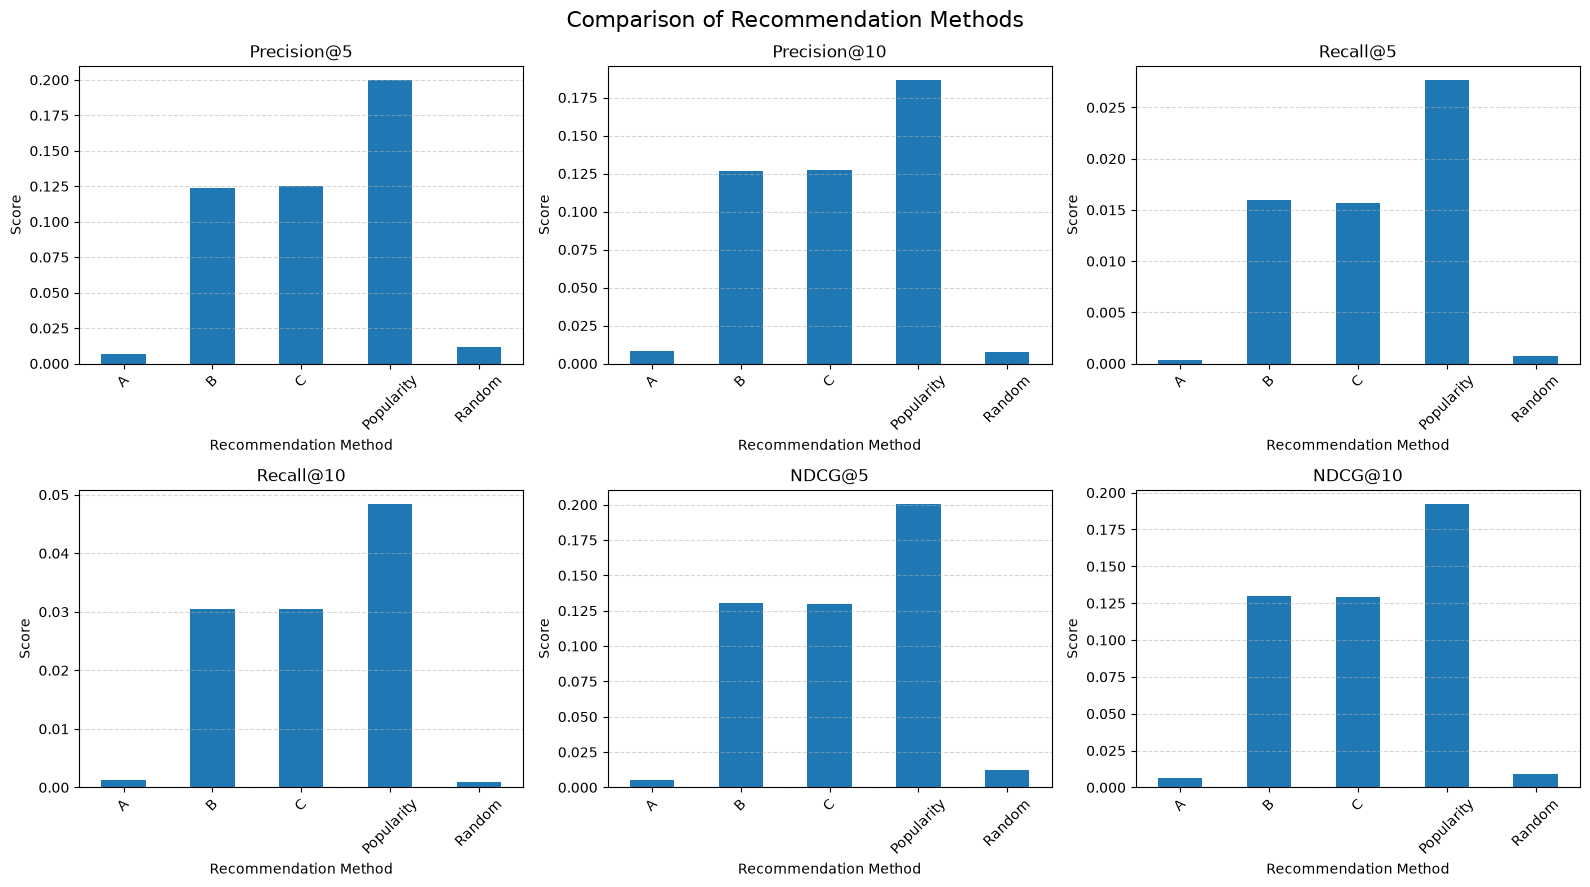

Graph saved successfully!


In [41]:
import matplotlib.pyplot as plt
import os

# Create output folder if it does not exist
os.makedirs("../outputs/figures", exist_ok=True)

# Prepare comparison data
plot_data = final_comparison.set_index("Method")

metrics = [
    "Precision@5",
    "Precision@10",
    "Recall@5",
    "Recall@10",
    "NDCG@5",
    "NDCG@10"
]

# Create six comparison charts
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, metric in enumerate(metrics):

    plot_data[metric].plot(
        kind="bar",
        ax=axes[i],
        title=metric
    )

    axes[i].set_xlabel("Recommendation Method")
    axes[i].set_ylabel("Score")
    axes[i].tick_params(axis="x", rotation=45)
    axes[i].grid(axis="y", linestyle="--", alpha=0.5)

plt.suptitle(
    "Comparison of Recommendation Methods",
    fontsize=16
)

plt.tight_layout()

# Save the graph
fig.savefig(
    "../outputs/figures/user_cold_start_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph saved successfully!")

### 6.9.1 Onboarding Preference Impact

This graph compares the impact of different levels of user onboarding preferences.

- Level A: Genres only
- Level B: Genres and favourite movies
- Level C: Genres, favourite movies, actors and directors

The comparison uses Precision@10, Recall@10 and NDCG@10.

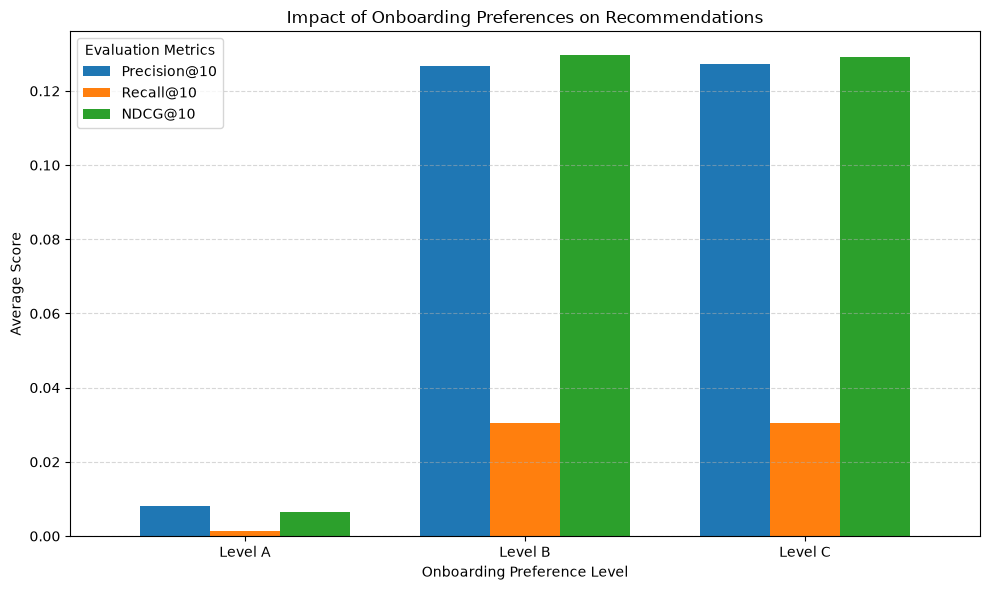

Onboarding preference impact graph saved successfully!


In [42]:
# Calculate average metrics for onboarding levels
onboarding_impact = (
    evaluation_results_df[
        evaluation_results_df["level"].isin(["A", "B", "C"])
    ]
    .groupby("level")[
        ["Precision@10", "Recall@10", "NDCG@10"]
    ]
    .mean()
)

# Create the figure
fig, ax = plt.subplots(figsize=(10, 6))

onboarding_impact.plot(
    kind="bar",
    ax=ax,
    width=0.75
)

ax.set_title("Impact of Onboarding Preferences on Recommendations")
ax.set_xlabel("Onboarding Preference Level")
ax.set_ylabel("Average Score")
ax.set_xticklabels(["Level A", "Level B", "Level C"], rotation=0)

ax.legend(title="Evaluation Metrics")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Save the graph
fig.savefig(
    "../outputs/figures/onboarding_preference_impact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Onboarding preference impact graph saved successfully!")

## 6.10 Saving Results

This section saves the recommendation evaluation results and onboarding comparison into CSV files.

The saved files can be used for project analysis, reporting and documentation.

In [43]:
import os
import pandas as pd

# Create results folder
os.makedirs("../outputs/results", exist_ok=True)

# Prepare user-level evaluation results
user_results = evaluation_results_df.rename(
    columns={"level": "method"}
)

# Combine preference-based and baseline results
all_results = pd.concat(
    [user_results, baseline_results_df],
    ignore_index=True
)

# Save complete user-level results
all_results.to_csv(
    "../outputs/results/user_cold_start_results.csv",
    index=False
)

# Save onboarding comparison (Levels A, B and C)
level_comparison.to_csv(
    "../outputs/results/onboarding_comparison.csv",
    index=False
)

print("Results saved successfully!")

print("User-level results:", all_results.shape)
print("Onboarding comparison:", level_comparison.shape)

Results saved successfully!
User-level results: (750, 8)
Onboarding comparison: (3, 7)


In [44]:
import ipywidgets as widgets
from IPython.display import display

print("Onboarding interface library is ready!")

Onboarding interface library is ready!


## 6.11 User Onboarding Interface

This section creates a simple interactive interface for new users.

Users can select:
- Favourite genres
- Favourite movies
- Favourite actors
- Favourite directors

The system uses these preferences to generate Top-10 movie recommendations.

In [45]:
from IPython.display import display, clear_output
import ipywidgets as widgets
import re

# Extract available genres
genre_options = sorted(set(
    genre.strip()
    for value in movie_features_model["genres"].dropna()
    for genre in re.split(r"[|,]", str(value))
    if genre.strip()
))

# Extract actor tokens
actor_options = sorted(set(
    token
    for value in movie_features_model["actor_token"].dropna()
    for token in str(value).split()
    if token.startswith("actor_")
))

# Extract director tokens
director_options = sorted(set(
    token
    for value in movie_features_model["director_token"].dropna()
    for token in str(value).split()
    if token.startswith("dir_")
))

# Select popular movies for the movie selection list
movie_popularity = (
    train_without_cold.groupby("movieID")
    .size()
    .reset_index(name="rating_count")
    .sort_values("rating_count", ascending=False)
)

movie_options_df = movie_popularity.merge(
    movie_features_model[["movieID", "title"]],
    on="movieID",
    how="inner"
).drop_duplicates("movieID").head(300)

movie_options = [
    (f"{row.title} ({row.movieID})", int(row.movieID))
    for row in movie_options_df.itertuples()
]

# Create selection widgets
genre_widget = widgets.SelectMultiple(
    options=genre_options,
    description="Genres:",
    rows=6,
    layout=widgets.Layout(width="80%")
)

movie_widget = widgets.SelectMultiple(
    options=movie_options,
    description="Movies:",
    rows=8,
    layout=widgets.Layout(width="80%")
)

actor_widget = widgets.SelectMultiple(
    options=actor_options,
    description="Actors:",
    rows=6,
    layout=widgets.Layout(width="80%")
)

director_widget = widgets.SelectMultiple(
    options=director_options,
    description="Directors:",
    rows=6,
    layout=widgets.Layout(width="80%")
)

recommend_button = widgets.Button(
    description="Get Recommendations",
    button_style="success",
    icon="film"
)

output = widgets.Output()

# Recommendation button action
def get_user_recommendations(button):

    with output:
        clear_output()

        preferences = {
            "genres": list(genre_widget.value),
            "movies": list(movie_widget.value),
            "actors": list(actor_widget.value),
            "directors": list(director_widget.value)
        }

        if not any(preferences.values()):
            print("Please select at least one preference.")
            return

        recommendations = recommend_movies(
            preferences,
            top_n=10
        )

        print("Your Top-10 Movie Recommendations:")

        display(recommendations)

# Connect button to function
recommend_button.on_click(get_user_recommendations)

# Display the onboarding interface
display(
    widgets.VBox([
        widgets.HTML("<h3>Welcome! Select Your Movie Preferences</h3>"),
        genre_widget,
        movie_widget,
        actor_widget,
        director_widget,
        recommend_button,
        output
    ])
)

## 6.12 Importing Functions from Source File

This section imports reusable functions from the `src/user_cold_start.py` module.

This keeps the project organized and avoids repeating code.

In [46]:
import sys
import os

# Add src folder to Python path
sys.path.insert(0, os.path.abspath("../src"))

# Import reusable functions
from user_cold_start import (
    build_tfidf_model,
    recommend_for_new_user,
    precision_at_k,
    recall_at_k,
    ndcg_at_k,
    catalog_coverage
)

print("All functions imported successfully!")

All functions imported successfully!


### 6.12.1 Testing Imported Recommendation Function

This section tests the recommendation function imported from the source file using an existing cold-start user's preferences.

In [47]:
# Build the TF-IDF model using movie features
cold_start_model = build_tfidf_model(movie_features_model)

# Select one cold-start user
test_user_id = cold_users[0]

# Get this user's Level C preferences
test_preferences = preferences_C[test_user_id]

# Exclude all onboarding movies
excluded_movies = user_onboarding[test_user_id]["movieID"].tolist()

# Generate recommendations using the imported function
source_recommendations = recommend_for_new_user(
    preferences=test_preferences,
    movie_features=movie_features_model,
    top_n=10,
    user_id=test_user_id,
    exclude_movie_ids=excluded_movies,
    model=cold_start_model
)

print("Recommendations generated using src/user_cold_start.py:")
display(source_recommendations)

Recommendations generated using src/user_cold_start.py:


,movieID,title,genres,similarity
0,59501,The Chronicles of Narnia: Prince Caspian,Adventure Children Fantasy,0.360769
1,4993,The Lord of the Rings: The Fellowship of the Ring,Action Adventure Fantasy,0.290729
2,7153,The Lord of the Rings: The Return of the King,Action Adventure Fantasy,0.279260
3,1339,Dracula,Fantasy Horror Romance Thriller,0.271847
4,898,The Philadelphia Story,Comedy Romance,0.265440
5,5952,The Lord of the Rings: The Two Towers,Action Adventure Fantasy,0.260391
6,1198,Raiders of the Lost Ark,Action Adventure,0.258992
7,260,Star Wars,Action Adventure Sci-Fi,0.254567
8,593,The Silence of the Lambs,Crime Horror Thriller,0.236082
9,920,Gone with the Wind,Drama Romance War,0.217640


In [48]:
# Check whether onboarding movies appear in recommendations

recommended_ids = set(source_recommendations["movieID"])

onboarding_ids = set(
    user_onboarding[test_user_id]["movieID"]
)

overlap = recommended_ids.intersection(onboarding_ids)

print("Number of recommendations:", len(recommended_ids))
print("Number of onboarding movies:", len(onboarding_ids))
print("Overlapping movies:", len(overlap))

if len(overlap) == 0:
    print("PASS: No onboarding movies appear in recommendations.")
else:
    print("FAIL: Some onboarding movies appear in recommendations.")

Number of recommendations: 10
Number of onboarding movies: 32
Overlapping movies: 0
PASS: No onboarding movies appear in recommendations.
